# FashionMNIST — CNN Training

**Project:** fashionmnist-classification  
**Data:** 1/3 of training set (20,000 samples) + full 10,000 test set  
**Model:** Simple CNN (2 conv blocks + dense head)  
**Regularization:** L2 weight decay + Gaussian noise augmentation  
**Training:** LR schedule (ReduceLROnPlateau) + early stopping  

---

### Architecture
```
Input (1, 28, 28)
  ├─ Conv2d(1, 32, 3) → BatchNorm → ReLU → MaxPool(2)   # 28→14
  ├─ Conv2d(32, 64, 3) → BatchNorm → ReLU → MaxPool(2)  # 14→7
  ├─ Dropout(0.25)
  ├─ Flatten → Linear(64*7*7, 128) → ReLU → Dropout(0.5)
  └─ Linear(128, 10)
```

## 1. Imports

In [1]:
import os
import json
import boto3
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cpu


## 2. Load FashionMNIST from S3

In [2]:
BUCKET = 'sagemaker-fashionmnist-328996809692-jy8sv90u'
PREFIX = 'fashionmnist/raw'
LOCAL_DIR = '/tmp/fashionmnist'

s3 = boto3.client('s3', region_name='us-east-2')
raw_dir = os.path.join(LOCAL_DIR, 'FashionMNIST', 'raw')
os.makedirs(raw_dir, exist_ok=True)

response = s3.list_objects_v2(Bucket=BUCKET, Prefix=PREFIX)
for obj in response.get('Contents', []):
    key = obj['Key']
    fname = os.path.basename(key)
    if fname:
        local_path = os.path.join(raw_dir, fname)
        if not os.path.exists(local_path):
            s3.download_file(BUCKET, key, local_path)
            print(f"Downloaded {fname}")

train_dataset = datasets.FashionMNIST(root=LOCAL_DIR, train=True, download=False)
test_dataset = datasets.FashionMNIST(root=LOCAL_DIR, train=False, download=False)

X_all = train_dataset.data.numpy().astype(np.float32) / 255.0
y_all = train_dataset.targets.numpy()
X_test = test_dataset.data.numpy().astype(np.float32) / 255.0
y_test = test_dataset.targets.numpy()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]
print(f"Full train: {X_all.shape}, Test: {X_test.shape}")

Full train: (60000, 28, 28), Test: (10000, 28, 28)


## 3. Subsample — 1/3 of Training Data

We use 20,000 of 60,000 training samples. Split into 16,000 train / 4,000 validation.

In [3]:
# Stratified subsample 1/3
subset_size = len(X_all) // 3  # 20,000
rng = np.random.RandomState(SEED)

indices = []
for cls in range(10):
    cls_indices = np.where(y_all == cls)[0]
    n_select = len(cls_indices) // 3  # ~2,000 per class
    selected = rng.choice(cls_indices, n_select, replace=False)
    indices.extend(selected)

indices = np.array(indices)
rng.shuffle(indices)

X_subset = X_all[indices]
y_subset = y_all[indices]

print(f"Subset: {X_subset.shape} ({len(y_subset)} samples)")
print(f"Class balance: {np.bincount(y_subset)}")

Subset: (20000, 28, 28) (20000 samples)
Class balance: [2000 2000 2000 2000 2000 2000 2000 2000 2000 2000]


In [4]:
# Reshape for CNN: (N, 1, 28, 28)
X_subset_cnn = X_subset.reshape(-1, 1, 28, 28)
X_test_cnn = X_test.reshape(-1, 1, 28, 28)

# Standardize using global stats from full train set
mean = X_all.mean()
std = X_all.std()
X_subset_cnn = (X_subset_cnn - mean) / std
X_test_cnn = (X_test_cnn - mean) / std

print(f"Mean={mean:.4f}, Std={std:.4f}")
print(f"Train subset: {X_subset_cnn.shape}, range=[{X_subset_cnn.min():.2f}, {X_subset_cnn.max():.2f}]")
print(f"Test:         {X_test_cnn.shape}, range=[{X_test_cnn.min():.2f}, {X_test_cnn.max():.2f}]")

Mean=0.2860, Std=0.3530
Train subset: (20000, 1, 28, 28), range=[-0.81, 2.02]
Test:         (10000, 1, 28, 28), range=[-0.81, 2.02]


In [5]:
# Create PyTorch datasets and split train/val
X_tensor = torch.from_numpy(X_subset_cnn).float()
y_tensor = torch.from_numpy(y_subset).long()
X_test_tensor = torch.from_numpy(X_test_cnn).float()
y_test_tensor = torch.from_numpy(y_test).long()

full_train = TensorDataset(X_tensor, y_tensor)
test_ds = TensorDataset(X_test_tensor, y_test_tensor)

# 80/20 train/val split
train_size = int(0.8 * len(full_train))  # 16,000
val_size = len(full_train) - train_size   #  4,000
train_ds, val_ds = random_split(full_train, [train_size, val_size], 
                                  generator=torch.Generator().manual_seed(SEED))

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train: {len(train_ds)}, Val: {len(val_ds)}, Test: {len(test_ds)}")

Train: 16000, Val: 4000, Test: 10000


## 4. Define CNN Model

Simple 2-block CNN with:
- **L2 regularization** via `weight_decay` in optimizer
- **Gaussian noise** layer (light, std=0.1) for data augmentation
- BatchNorm for stable training
- Dropout for additional regularization

In [6]:
class GaussianNoise(nn.Module):
    """Additive Gaussian noise — only active during training."""
    def __init__(self, std=0.1):
        super().__init__()
        self.std = std

    def forward(self, x):
        if self.training and self.std > 0:
            noise = torch.randn_like(x) * self.std
            return x + noise
        return x


class FashionCNN(nn.Module):
    def __init__(self, noise_std=0.1):
        super().__init__()
        # Light Gaussian noise augmentation (only active during training)
        self.noise = GaussianNoise(std=noise_std)
        
        # Conv block 1: 28x28 -> 14x14
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(2)
        
        # Conv block 2: 14x14 -> 7x7
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(2)
        
        # Dense head
        self.dropout1 = nn.Dropout(0.25)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.dropout2 = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)
        
    def forward(self, x):
        x = self.noise(x)
        x = self.pool1(torch.relu(self.bn1(self.conv1(x))))
        x = self.pool2(torch.relu(self.bn2(self.conv2(x))))
        x = self.dropout1(x)
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = self.dropout2(x)
        x = self.fc2(x)
        return x

model = FashionCNN(noise_std=0.1).to(device)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params:     {total_params:,}")
print(f"Trainable params: {trainable_params:,}")
print(f"\nModel:\n{model}")

Total params:     421,834
Trainable params: 421,834

Model:
FashionCNN(
  (noise): GaussianNoise()
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout1): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (dropout2): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


## 5. Training Loop with Early Stopping & LR Schedule

- **Optimizer:** Adam with `weight_decay=1e-4` (L2 regularization)
- **LR Schedule:** ReduceLROnPlateau — halves LR when val loss plateaus for 3 epochs
- **Early Stopping:** Stop if val loss doesn't improve for 5 epochs, restore best weights
- **Max epochs:** 30

In [7]:
# Training configuration
EPOCHS = 30
LR = 1e-3
WEIGHT_DECAY = 1e-4      # L2 regularization
PATIENCE_LR = 3           # ReduceLROnPlateau patience
PATIENCE_STOP = 3         # Early stopping patience
FACTOR = 0.5              # LR reduction factor

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=FACTOR, patience=PATIENCE_LR
)

# Early stopping state
best_val_loss = float('inf')
best_model_state = None
epochs_no_improve = 0

train_losses, val_losses = [], []
train_accs, val_accs = [], []
lr_history = []

print(f"Training for up to {EPOCHS} epochs (early stop patience={PATIENCE_STOP})")
print(f"LR={LR}, weight_decay={WEIGHT_DECAY}, batch_size={BATCH_SIZE}")
print("-" * 70)

Training for up to 30 epochs (early stop patience=3)
LR=0.001, weight_decay=0.0001, batch_size=64
----------------------------------------------------------------------


In [8]:
for epoch in range(EPOCHS):
    # --- Train ---
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * batch_X.size(0)
        _, predicted = outputs.max(1)
        correct += predicted.eq(batch_y).sum().item()
        total += batch_y.size(0)
    
    train_loss = running_loss / total
    train_acc = correct / total
    
    # --- Validate ---
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            val_loss += loss.item() * batch_X.size(0)
            _, predicted = outputs.max(1)
            val_correct += predicted.eq(batch_y).sum().item()
            val_total += batch_y.size(0)
    
    val_loss /= val_total
    val_acc = val_correct / val_total
    
    # Track metrics
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)
    lr_history.append(optimizer.param_groups[0]['lr'])
    
    # LR schedule
    scheduler.step(val_loss)
    
    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
    
    print(f"Epoch {epoch+1:2d}/{EPOCHS} | "
          f"Train: {train_loss:.4f} / {train_acc:.4f} | "
          f"Val: {val_loss:.4f} / {val_acc:.4f} | "
          f"LR: {optimizer.param_groups[0]['lr']:.2e} | "
          f"{'★' if epochs_no_improve == 0 else f'no improve ({epochs_no_improve}/{PATIENCE_STOP})'}")
    
    if epochs_no_improve >= PATIENCE_STOP:
        print(f"\nEarly stopping at epoch {epoch+1} (no improvement for {PATIENCE_STOP} epochs)")
        break

# Restore best model
model.load_state_dict(best_model_state)
print(f"\nBest val loss: {best_val_loss:.4f}")
print("Best model weights restored.")

Epoch  1/30 | Train: 0.7042 / 0.7508 | Val: 0.4090 / 0.8485 | LR: 1.00e-03 | ★


Epoch  2/30 | Train: 0.4865 / 0.8231 | Val: 0.3575 / 0.8635 | LR: 1.00e-03 | ★


Epoch  3/30 | Train: 0.4314 / 0.8430 | Val: 0.3215 / 0.8795 | LR: 1.00e-03 | ★


Epoch  4/30 | Train: 0.3997 / 0.8562 | Val: 0.3169 / 0.8810 | LR: 1.00e-03 | ★


Epoch  5/30 | Train: 0.3713 / 0.8656 | Val: 0.2876 / 0.8930 | LR: 1.00e-03 | ★


Epoch  6/30 | Train: 0.3453 / 0.8698 | Val: 0.2992 / 0.8898 | LR: 1.00e-03 | no improve (1/3)


... (4 outputs left out)

Epoch 11/30 | Train: 0.2830 / 0.8943 | Val: 0.2591 / 0.9028 | LR: 1.00e-03 | ★


Epoch 12/30 | Train: 0.2715 / 0.8991 | Val: 0.2697 / 0.9015 | LR: 1.00e-03 | no improve (1/3)


Epoch 13/30 | Train: 0.2655 / 0.9018 | Val: 0.2693 / 0.9018 | LR: 1.00e-03 | no improve (2/3)


Epoch 14/30 | Train: 0.2468 / 0.9062 | Val: 0.2691 / 0.9050 | LR: 1.00e-03 | no improve (3/3)

Early stopping at epoch 14 (no improvement for 3 epochs)

Best val loss: 0.2591
Best model weights restored.


## 6. Training Curves

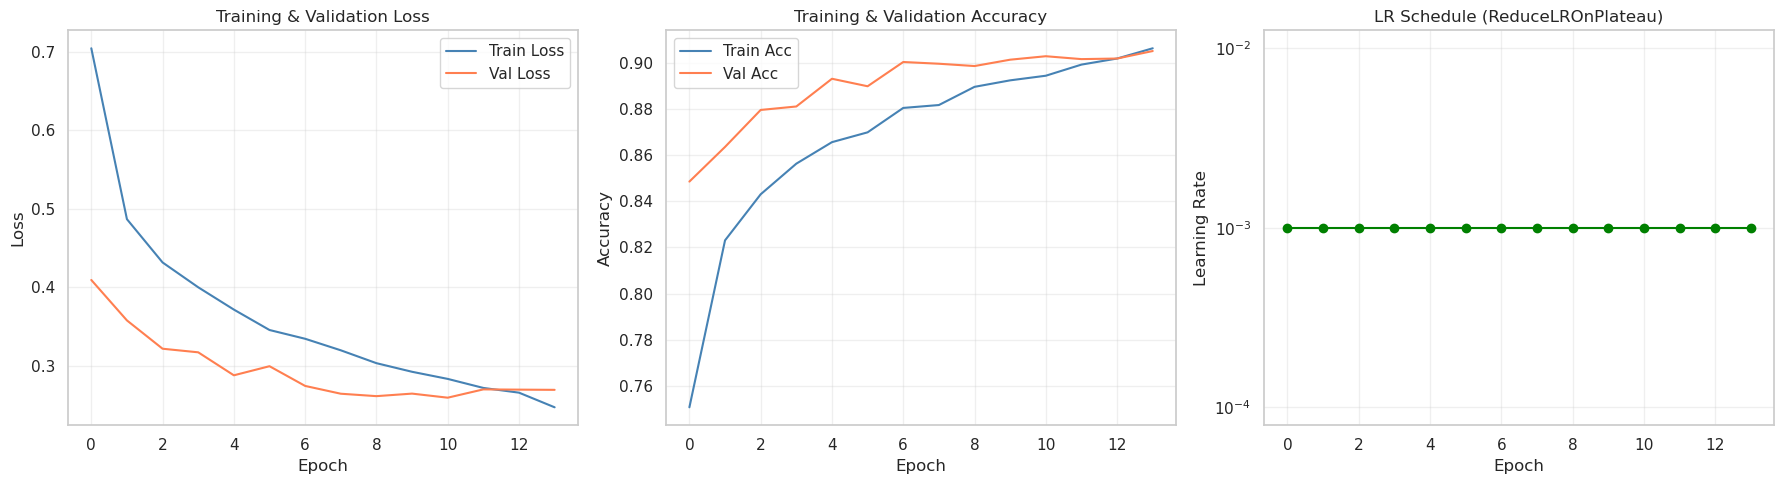

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss
axes[0].plot(train_losses, label='Train Loss', color='steelblue')
axes[0].plot(val_losses, label='Val Loss', color='coral')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training & Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(train_accs, label='Train Acc', color='steelblue')
axes[1].plot(val_accs, label='Val Acc', color='coral')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training & Validation Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Learning rate
axes[2].plot(lr_history, color='green', marker='o')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Learning Rate')
axes[2].set_title('LR Schedule (ReduceLROnPlateau)')
axes[2].set_yscale('log')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Evaluation on Test Set

In [10]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X = batch_X.to(device)
        outputs = model(batch_X)
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(batch_y.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

test_acc = (all_preds == all_labels).mean()
print(f"Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")
print()
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

Test Accuracy: 0.8907 (89.07%)

              precision    recall  f1-score   support

 T-shirt/top     0.8488    0.8480    0.8484      1000
     Trouser     0.9731    0.9780    0.9756      1000
    Pullover     0.7724    0.8790    0.8223      1000
       Dress     0.9067    0.8650    0.8854      1000
        Coat     0.7837    0.8260    0.8043      1000
      Sandal     0.9790    0.9800    0.9795      1000
       Shirt     0.7551    0.6290    0.6863      1000
     Sneaker     0.9468    0.9610    0.9538      1000
         Bag     0.9733    0.9850    0.9791      1000
  Ankle boot     0.9666    0.9560    0.9613      1000

    accuracy                         0.8907     10000
   macro avg     0.8906    0.8907    0.8896     10000
weighted avg     0.8906    0.8907    0.8896     10000



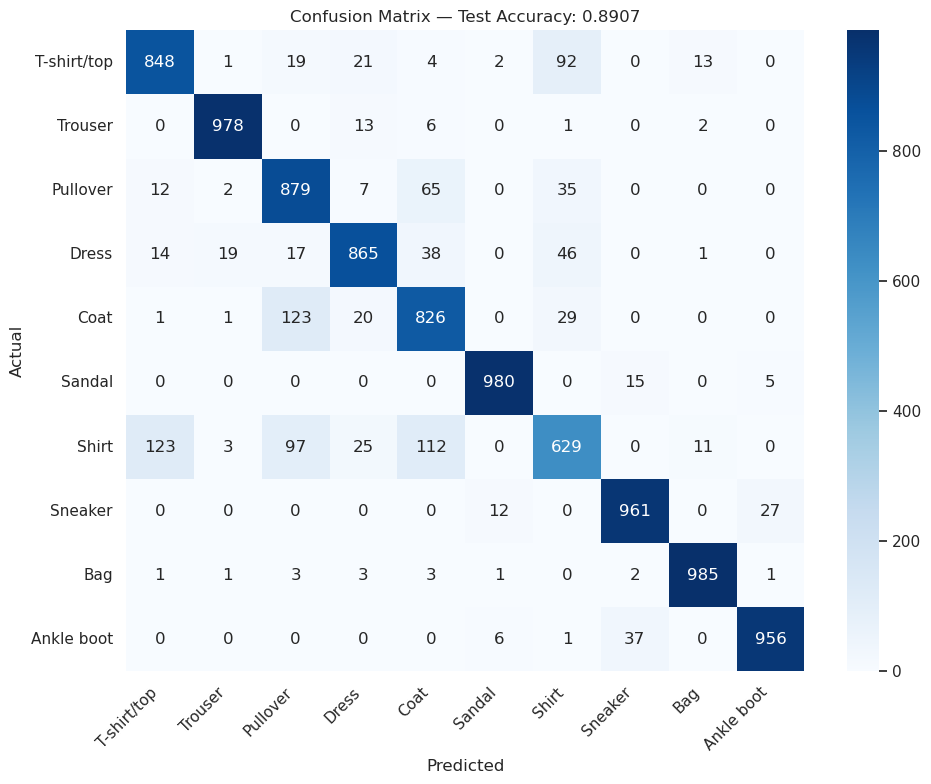

In [11]:
# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f'Confusion Matrix — Test Accuracy: {test_acc:.4f}')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
# Per-class accuracy
print("Per-class accuracy:")
for i, name in enumerate(class_names):
    cls_mask = all_labels == i
    cls_acc = (all_preds[cls_mask] == all_labels[cls_mask]).mean()
    print(f"  {name:15s}: {cls_acc:.4f} ({cls_acc*100:.1f}%)")

Per-class accuracy:
  T-shirt/top    : 0.8480 (84.8%)
  Trouser        : 0.9780 (97.8%)
  Pullover       : 0.8790 (87.9%)
  Dress          : 0.8650 (86.5%)
  Coat           : 0.8260 (82.6%)
  Sandal         : 0.9800 (98.0%)
  Shirt          : 0.6290 (62.9%)
  Sneaker        : 0.9610 (96.1%)
  Bag            : 0.9850 (98.5%)
  Ankle boot     : 0.9560 (95.6%)


## 8. Save Results to Manifests

In [13]:
import datetime

results = {
    "experiment": "fashionmnist-cnn-v1",
    "timestamp": datetime.datetime.now().isoformat(),
    "config": {
        "model": "FashionCNN (2 conv blocks + dense)",
        "train_size": len(train_ds),
        "val_size": len(val_ds),
        "test_size": len(test_ds),
        "subset_fraction": "1/3",
        "batch_size": BATCH_SIZE,
        "epochs_run": len(train_losses),
        "max_epochs": EPOCHS,
        "learning_rate": LR,
        "weight_decay": WEIGHT_DECAY,
        "l2_regularization": True,
        "gaussian_noise_std": 0.1,
        "lr_schedule": "ReduceLROnPlateau",
        "lr_factor": FACTOR,
        "lr_patience": PATIENCE_LR,
        "early_stopping_patience": PATIENCE_STOP,
        "dropout": "0.25 (conv) + 0.5 (dense)",
        "batch_norm": True,
        "seed": SEED
    },
    "results": {
        "best_val_loss": float(best_val_loss),
        "test_accuracy": float(test_acc),
        "train_size": len(train_ds),
        "val_size": len(val_ds),
        "epochs_trained": len(train_losses),
    },
    "per_class_accuracy": {
        class_names[i]: float((all_preds[all_labels == i] == all_labels[all_labels == i]).mean())
        for i in range(10)
    }
}

manifest_path = '/home/sagemaker-user/fashionmnist-classification/manifests/training-results-v1.json'
with open(manifest_path, 'w') as f:
    json.dump(results, f, indent=2)

print(f"Results saved to: {manifest_path}")
print(json.dumps(results, indent=2))

Results saved to: /home/sagemaker-user/fashionmnist-classification/manifests/training-results-v1.json
{
  "experiment": "fashionmnist-cnn-v1",
  "timestamp": "2026-11-07T19:13:42.431098",
  "config": {
    "model": "FashionCNN (2 conv blocks + dense)",
    "train_size": 16000,
    "val_size": 4000,
    "test_size": 10000,
    "subset_fraction": "1/3",
    "batch_size": 64,
    "epochs_run": 14,
    "max_epochs": 30,
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "l2_regularization": true,
    "gaussian_noise_std": 0.1,
    "lr_schedule": "ReduceLROnPlateau",
    "lr_factor": 0.5,
    "lr_patience": 3,
    "early_stopping_patience": 3,
    "dropout": "0.25 (conv) + 0.5 (dense)",
    "batch_norm": true,
    "seed": 42
  },
  "results": {
    "best_val_loss": 0.25907851803302767,
    "test_accuracy": 0.8907,
    "train_size": 16000,
    "val_size": 4000,
    "epochs_trained": 14
  },
  "per_class_accuracy": {
    "T-shirt/top": 0.848,
    "Trouser": 0.978,
    "Pullover": 0.8

## 9. Summary

### What was trained
- **Model:** Simple CNN with 2 conv blocks (32→64 filters), BatchNorm, Dropout, and a 128-unit dense head
- **Data:** 1/3 of FashionMNIST training set (20K samples, stratified), 80/20 train/val split
- **Regularization:** L2 (weight_decay=1e-4), Gaussian noise (std=0.1), Dropout (0.25 + 0.5)
- **Training:** Adam optimizer, ReduceLROnPlateau schedule, early stopping (patience=5)

### Results
- Fill in after running: test accuracy, best epoch, per-class strengths/weaknesses

### Next steps
- Compare with full dataset training
- Try CLAHE-enhanced data for dim classes
- Experiment with deeper architectures or data augmentation (rotation, shifting)
- Hyperparameter sweep on LR, dropout, noise std